# Problem 2 — Transformers from scratch (P1 h=64; chosen configuration: d=64, seeds 17/42/2026)

The assignment uses recurrent hidden size $h=64$, Transformer width $d=64$, and seeds $(17,42,2026)$. The chosen $d=64$ is divisible by all head counts used: 1, 4, and 8. Attention, multi-head projections, sinusoidal positions, pre-LayerNorm blocks, encoder classification, and a causal character model are implemented from scratch with tensor operations.

In [ ]:
# --- Reproducibility, paths, and experiment budgets ---
from pathlib import Path

# Resolve the repository root whether Jupyter starts at the workspace or inside problem2/.
ROOT = Path.cwd()
if not (ROOT / 'requirements.txt').exists() and (ROOT.parent / 'requirements.txt').exists():
    ROOT = ROOT.parent

import torch
import matplotlib.pyplot as plt

# Keep figures, checkpoints, samples, and attention diagnostics in Problem 2 artifacts.
P2_DIR = ROOT / 'problem2'
P2_FIGURES = P2_DIR / 'figures'
P2_CHECKPOINTS = P2_DIR / 'checkpoints'
P2_SAMPLES = P2_DIR / 'generated_samples.txt'
P2_MASK_SAMPLES = P2_DIR / 'mask_ablation_samples.txt'
P2_ATTENTION_ANALYSIS = P2_DIR / 'attention_heatmap_analysis.txt'
for directory in (P2_DIR, P2_FIGURES, P2_CHECKPOINTS):
    directory.mkdir(parents=True, exist_ok=True)

# Use fixed seeds and one shared d=64, four-head, four-layer, context-128 architecture.
SEEDS = (17, 42, 2026)
P2_D_MODEL = 64
P2_HEADS = 4
P2_LAYERS = 4
P2_CONTEXT = 128
# Preserve the stated HAR, language-model, ablation, and minibatch budgets.
P2_HAR_EPOCHS = 20
P2_HAR_BATCH_SIZE = 64
LM_STEPS = 1_000
ABLATION_STEPS = 500
P2_LM_BATCH_SIZE = 8
# Every compared head count must divide d_model so each head has an integer width.
for heads in (1, 4, 8):
    assert P2_D_MODEL % heads == 0

# Prefer CUDA when available and share the repository-wide results table.
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RESULTS = ROOT / 'results.csv'
# Stable model IDs encode the current architecture and positional variants.
P2_BASE_MODEL = f'causal-transformer-d{P2_D_MODEL}-h{P2_HEADS}-l{P2_LAYERS}'
P2_HAR_MODELS = tuple(
    f'encoder-{positional}-d{P2_D_MODEL}-h{P2_HEADS}-l{P2_LAYERS}'
    for positional in ('none', 'sinusoidal', 'learned')
)
print('device:', DEVICE)
print(
    f'chosen configuration: h=64, d={P2_D_MODEL}, seeds={SEEDS}; '
    f'heads={P2_HEADS}, layers={P2_LAYERS}, context={P2_CONTEXT}'
)

device: cuda
chosen configuration: h=64, d=64, seeds=(17, 42, 2026); heads=4, layers=4, context=128


In [ ]:
"""Problem 2 data, training, and result utilities."""

from __future__ import annotations

import csv
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

RESULT_COLUMNS = (
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats",
    "bits_per_char", "notes",
)
HAR_CHANNELS = (
    "body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y",
    "body_gyro_z", "total_acc_x", "total_acc_y", "total_acc_z",
)


# --- Data and training helpers ---

# Seed Python, NumPy, and every available Torch device for repeatable runs.
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Read one whitespace-delimited HAR matrix as float32.
def _read_matrix(path: Path) -> np.ndarray:
    return np.loadtxt(path, dtype=np.float32)


# Load HAR windows with a subject-wise split and training-only normalization.
def load_har(root: str | Path, validation_seed: int = 0) -> dict[str, np.ndarray]:
    """Load HAR windows with a reproducible subject-wise validation split."""
    root = Path(root)
    dataset_dir = root / "UCI HAR Dataset"
    if not dataset_dir.exists():
        root.mkdir(parents=True, exist_ok=True)
        archive = root / "har.zip"
        url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
        urllib.request.urlretrieve(url, archive)
        with zipfile.ZipFile(archive) as archive_file:
            archive_file.extractall(root)
        nested = root / "UCI HAR Dataset.zip"
        if nested.exists():
            with zipfile.ZipFile(nested) as archive_file:
                archive_file.extractall(root)

    # Stack all nine inertial channels and retain subject IDs for grouped splitting.
    def split(part: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        folder = dataset_dir / part
        signal_dir = folder / "Inertial Signals"
        signals = [
            _read_matrix(signal_dir / f"{name}_{part}.txt") for name in HAR_CHANNELS
        ]
        inputs = np.stack(signals, axis=-1)
        targets = _read_matrix(folder / f"y_{part}.txt").astype(np.int64) - 1
        subjects = _read_matrix(folder / f"subject_{part}.txt").astype(np.int64)
        return inputs, targets, subjects

    train_inputs, train_targets, train_subjects = split("train")
    test_inputs, test_targets, _ = split("test")
    subjects = np.unique(train_subjects)
    # Hold out complete people so windows from one subject cannot leak across splits.
    validation_subjects = np.random.default_rng(validation_seed).choice(
        subjects, 4, replace=False
    )
    validation_mask = np.isin(train_subjects, validation_subjects)
    training_mask = ~validation_mask
    # Fit channel statistics on training subjects only, then reuse them unchanged.
    mean = train_inputs[training_mask].mean(axis=(0, 1), keepdims=True)
    std = train_inputs[training_mask].std(axis=(0, 1), keepdims=True)
    std[std == 0] = 1
    return {
        "x_train": ((train_inputs[training_mask] - mean) / std).astype(np.float32),
        "y_train": train_targets[training_mask],
        "x_val": ((train_inputs[validation_mask] - mean) / std).astype(np.float32),
        "y_val": train_targets[validation_mask],
        "x_test": ((test_inputs - mean) / std).astype(np.float32),
        "y_test": test_targets,
        "val_subjects": validation_subjects,
    }


# Train a supervised model and restore the lowest-validation-loss checkpoint.
def train_model(
    model: nn.Module,
    train_x: np.ndarray,
    train_y: np.ndarray,
    val_x: np.ndarray,
    val_y: np.ndarray,
    *,
    task: str,
    epochs: int = 20,
    batch_size: int = 128,
    lr: float = 1e-3,
    device: str | torch.device = "cpu",
) -> tuple[nn.Module, list[float], float]:
    """Train with Adam and restore the lowest-validation-loss checkpoint."""
    device = torch.device(device)
    model = model.to(device)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_x), torch.from_numpy(train_y)),
        batch_size=batch_size,
        shuffle=True,
    )
    val_inputs = torch.from_numpy(val_x).to(device)
    val_targets = torch.from_numpy(val_y).to(device)
    loss_fn = nn.CrossEntropyLoss() if task == "classification" else nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss = float("inf")
    best_state = None
    curve: list[float] = []
    epoch_seconds = []
    for _ in range(epochs):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        started = time.perf_counter()
        model.train()
        for batch_inputs, batch_targets in loader:
            batch_inputs = batch_inputs.to(device)
            batch_targets = batch_targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(batch_inputs), batch_targets)
            loss.backward()
            optimizer.step()
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        epoch_seconds.append(time.perf_counter() - started)
        model.eval()
        with torch.no_grad():
            val_loss = float(loss_fn(model(val_inputs), val_targets).item())
        curve.append(val_loss)
        if val_loss < best_loss:
            # Snapshot on CPU so final evaluation uses validation selection, not the last epoch.
            best_loss = val_loss
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
    if best_state is None:
        raise RuntimeError("Training completed without a validation checkpoint")
    model.load_state_dict(best_state)
    return model, curve, float(np.mean(epoch_seconds))


# Append one schema-aligned row and emit the header only when creating the CSV.
def append_result(path: str | Path, row: dict[str, object]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    write_header = not path.exists()
    with path.open("a", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=RESULT_COLUMNS)
        if write_header:
            writer.writeheader()
        writer.writerow({column: row.get(column, "") for column in RESULT_COLUMNS})

In [ ]:
"""From-scratch Transformer components and Problem 2 task helpers."""

from __future__ import annotations

import math
import time
import urllib.request
from pathlib import Path
from typing import Literal

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F


# Compute scaled dot-product attention for q/k/v tensors shaped (B,H,T,Dh).
def scaled_dot_product_attention(
    q: torch.Tensor,
    k: torch.Tensor,
    v: torch.Tensor,
    mask: torch.Tensor | None = None,
    dropout: nn.Module | None = None,
) -> tuple[torch.Tensor, torch.Tensor]:
    if q.ndim != 4 or k.ndim != 4 or v.ndim != 4:
        raise ValueError("q, k and v must have shape (batch, heads, tokens, head_dim)")
    if q.shape[:2] != k.shape[:2] or k.shape[:2] != v.shape[:2]:
        raise ValueError("q, k and v batch/head dimensions must agree")
    if q.shape[-1] != k.shape[-1] or k.shape[-2] != v.shape[-2]:
        raise ValueError("incompatible query/key dimensions or key/value lengths")
    # QK^T gives scores (B,H,Tq,Tk); sqrt(Dh) prevents large logits as head width grows.
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])
    if mask is not None:
        if mask.shape[-2:] != scores.shape[-2:]:
            raise ValueError("mask's final dimensions must match query/key lengths")
        if mask.dtype == torch.bool:
            # True means visible; masked keys receive -inf before row-wise softmax.
            if not torch.all(mask.any(dim=-1)):
                raise ValueError("every query must have at least one unmasked key")
            scores = scores.masked_fill(~mask, -torch.inf)
        else:
            # Additive masks contribute finite penalties or -inf directly to score logits.
            scores = scores + mask.to(device=scores.device, dtype=scores.dtype)
            if not torch.all(torch.isfinite(scores).any(dim=-1)):
                raise ValueError("additive mask fully masks at least one query")
    # Normalize across keys, optionally drop probabilities, then form weighted value sums.
    weights = scores.softmax(dim=-1)
    attended = (dropout(weights) if dropout is not None else weights) @ v
    return attended, weights


# Project model-width tokens into multiple attention heads and merge their attended values.
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.0):
        super().__init__()
        if d_model % n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        # Independent learned Q/K/V projections preserve model width before head splitting.
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.attention_dropout = nn.Dropout(dropout)

    def forward(
        self, x: torch.Tensor, mask: torch.Tensor | None = None, *,
        need_weights: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        batch, tokens, _ = x.shape

        # Reshape (B,T,d) to (B,H,T,Dh) so heads attend independently.
        def split_heads(projected: torch.Tensor) -> torch.Tensor:
            return projected.view(
                batch, tokens, self.n_heads, self.head_dim
            ).transpose(1, 2)

        q = split_heads(self.w_q(x))
        k = split_heads(self.w_k(x))
        v = split_heads(self.w_v(x))
        attended, weights = scaled_dot_product_attention(
            q, k, v, mask, self.attention_dropout
        )
        # Merge (B,H,T,Dh) back to contiguous (B,T,d) before the output projection.
        merged = attended.transpose(1, 2).contiguous().view(batch, tokens, self.d_model)
        result = self.w_o(merged)
        return (result, weights) if need_weights else result


# Add fixed sine/cosine position vectors without introducing trainable parameters.
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 8192):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        # Even dimensions use geometrically spaced frequencies; odd dimensions use cosines.
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10_000.0) / d_model)
        )
        encoding = torch.zeros(max_len, d_model)
        encoding[:, 0::2] = torch.sin(position * div_term)
        encoding[:, 1::2] = torch.cos(
            position * div_term[:encoding[:, 1::2].shape[1]]
        )
        self.register_buffer("encoding", encoding.unsqueeze(0), persistent=False)

    def forward(self, x: torch.Tensor, offset: int = 0) -> torch.Tensor:
        end = offset + x.shape[1]
        if offset < 0 or end > self.encoding.shape[1]:
            raise ValueError("requested positions exceed the configured positional range")
        return x + self.encoding[:, offset:end].to(dtype=x.dtype)


# Apply pre-LayerNorm attention and feed-forward residual branches.
class EncoderBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        # Expand features d -> 4d, apply GELU, then project 4d -> d for the residual sum.
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout),
        )
        self.residual_dropout = nn.Dropout(dropout)

    def forward(
        self, x: torch.Tensor, mask: torch.Tensor | None = None, *,
        need_weights: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        if need_weights:
            attended, weights = self.attention(self.norm1(x), mask, need_weights=True)
            x = x + self.residual_dropout(attended)
            x = x + self.feed_forward(self.norm2(x))
            return x, weights
        x = x + self.residual_dropout(self.attention(self.norm1(x), mask))
        return x + self.feed_forward(self.norm2(x))


# Encode HAR windows and classify from a prepended learned CLS token.
class EncoderClassifier(nn.Module):
    def __init__(
        self, input_size: int = 9, n_classes: int = 6,
        d_model: int = P2_D_MODEL, n_heads: int = P2_HEADS,
        n_layers: int = P2_LAYERS,
        positional: Literal["none", "sinusoidal", "learned"] = "sinusoidal",
        dropout: float = 0.1, max_len: int = P2_CONTEXT + 2,
    ):
        super().__init__()
        self.input_projection = nn.Linear(input_size, d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.positional = positional
        self.sinusoidal = SinusoidalPositionalEncoding(d_model, max_len)
        self.learned_positions = (
            nn.Embedding(max_len, d_model) if positional == "learned" else None
        )
        if positional not in ("none", "sinusoidal", "learned"):
            raise ValueError(f"Unknown positional encoding: {positional}")
        self.blocks = nn.ModuleList(
            EncoderBlock(d_model, n_heads, dropout) for _ in range(n_layers)
        )
        self.norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch, length, _ = x.shape
        embedded = self.input_projection(x)
        # CLS occupies position 0 and pools the full unmasked sequence through attention.
        hidden = torch.cat((self.cls_token.expand(batch, -1, -1), embedded), dim=1)
        if self.positional == "sinusoidal":
            hidden = self.sinusoidal(hidden)
        elif self.positional == "learned":
            positions = torch.arange(length + 1, device=x.device)
            hidden = hidden + self.learned_positions(positions).unsqueeze(0)
        for block in self.blocks:
            hidden = block(hidden)
        return self.classifier(self.norm(hidden[:, 0]))


# Build a character Transformer with tied token/output embeddings and optional causal masking.
class CausalTransformerLM(nn.Module):
    def __init__(
        self, vocab_size: int, d_model: int = P2_D_MODEL,
        n_heads: int = P2_HEADS, n_layers: int = P2_LAYERS,
        context: int = P2_CONTEXT, dropout: float = 0.1,
        causal: bool = True, max_positions: int = 8192,
    ):
        super().__init__()
        self.context = context
        self.causal = causal
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_encoding = SinusoidalPositionalEncoding(d_model, max_positions)
        self.blocks = nn.ModuleList(
            EncoderBlock(d_model, n_heads, dropout) for _ in range(n_layers)
        )
        self.norm = nn.LayerNorm(d_model)
        self.output = nn.Linear(d_model, vocab_size, bias=False)
        # Weight tying reuses one vocabulary matrix for input lookup and output logits.
        self.output.weight = self.token_embedding.weight

    def forward(
        self, tokens: torch.Tensor, *, position_offset: int = 0,
        return_attention: bool = False,
    ) -> torch.Tensor | tuple[torch.Tensor, list[torch.Tensor]]:
        _, length = tokens.shape
        if length > self.context:
            raise ValueError(f"input length {length} exceeds context {self.context}")
        hidden = self.position_encoding(
            self.token_embedding(tokens), offset=position_offset
        )
        mask = None
        if self.causal:
            # Lower-triangular True entries prevent each query from seeing future keys.
            mask = torch.ones(
                length, length, dtype=torch.bool, device=tokens.device
            ).tril()
        attentions = []
        for block in self.blocks:
            if return_attention:
                hidden, weights = block(hidden, mask, need_weights=True)
                attentions.append(weights)
            else:
                hidden = block(hidden, mask)
        logits = self.output(self.norm(hidden))
        # Attention inspection returns one (B,H,T,T) tensor per encoder block.
        return (logits, attentions) if return_attention else logits


# Compare attention with PyTorch and test normalization plus bool/additive mask behavior.
def test_attention() -> None:
    torch.manual_seed(11)
    q, k, v = (torch.randn(2, 3, 5, 8) for _ in range(3))
    actual, weights = scaled_dot_product_attention(q, k, v)
    expected = F.scaled_dot_product_attention(q, k, v)
    torch.testing.assert_close(actual, expected, atol=1e-5, rtol=1e-5)
    torch.testing.assert_close(weights.sum(-1), torch.ones_like(weights.sum(-1)))
    causal = torch.ones(5, 5, dtype=torch.bool).tril()
    _, causal_weights = scaled_dot_product_attention(q, k, v, causal)
    assert torch.count_nonzero(causal_weights.triu(diagonal=1)) == 0
    additive = torch.zeros(5, 5)
    additive[0] = -torch.inf
    try:
        scaled_dot_product_attention(q, k, v, additive)
    except ValueError as error:
        assert "fully masks" in str(error)
    else:
        raise AssertionError("fully masked additive row must be rejected")


# Verify nonzero absolute position offsets reproduce an explicit forward pass.
def test_absolute_generation_positions() -> None:
    model = CausalTransformerLM(
        vocab_size=11, d_model=8, n_heads=2, n_layers=1, context=4,
        dropout=0.0, max_positions=16,
    ).eval()
    tokens = torch.tensor([[1, 2, 3, 4]])
    direct = model(tokens, position_offset=3)
    expected_hidden = model.position_encoding(model.token_embedding(tokens), offset=3)
    mask = torch.ones(4, 4, dtype=torch.bool).tril()
    for block in model.blocks:
        expected_hidden = block(expected_hidden, mask)
    expected = model.output(model.norm(expected_hidden))
    torch.testing.assert_close(direct, expected)


# Download Tiny Shakespeare once and return its UTF-8 character stream.
def download_tiny_shakespeare(
    path: str | Path = "data/tinyshakespeare.txt",
) -> str:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        url = (
            "https://raw.githubusercontent.com/karpathy/char-rnn/"
            "master/data/tinyshakespeare/input.txt"
        )
        urllib.request.urlretrieve(url, path)
    return path.read_text(encoding="utf-8")


# Sort the vocabulary, encode characters as integers, and make a chronological 90/10 split.
def encode_shakespeare(
    text: str,
) -> tuple[torch.Tensor, torch.Tensor, dict[str, int]]:
    chars = sorted(set(text))
    stoi = {char: index for index, char in enumerate(chars)}
    data = torch.tensor([stoi[char] for char in text], dtype=torch.long)
    split = int(0.9 * len(data))
    return data[:split], data[split:], stoi


# Sample random context windows and their one-character-shifted language-model targets.
def sample_batch(
    data: torch.Tensor, batch_size: int, context: int, device: torch.device,
    *, generator: torch.Generator | None = None,
) -> tuple[torch.Tensor, torch.Tensor]:
    if len(data) <= context:
        raise ValueError("dataset must contain more tokens than the context length")
    starts = torch.randint(len(data) - context, (batch_size,), generator=generator)
    x = torch.stack([data[index:index + context] for index in starts])
    y = torch.stack([data[index + 1:index + context + 1] for index in starts])
    return x.to(device), y.to(device)


# Estimate deterministic train/validation loss with seeded batch generators.
def estimate_loss(
    model: CausalTransformerLM, train: torch.Tensor, val: torch.Tensor, *,
    batches: int = 20, batch_size: int = P2_LM_BATCH_SIZE,
    device: str | torch.device = "cpu", seed: int = 17,
) -> dict[str, float]:
    device = torch.device(device)
    result = {}
    was_training = model.training
    model.eval()
    with torch.no_grad():
        for split_index, (name, data) in enumerate((("train", train), ("val", val))):
            generator = torch.Generator().manual_seed(seed + split_index)
            losses = []
            for _ in range(batches):
                x, y = sample_batch(
                    data, batch_size, model.context, device, generator=generator
                )
                logits = model(x)
                # Flatten (B,T,V) logits and (B,T) targets for token-level cross-entropy.
                losses.append(F.cross_entropy(
                    logits.reshape(-1, logits.size(-1)), y.reshape(-1)
                ))
            result[name] = float(torch.stack(losses).mean().item())
    model.train(was_training)
    return result


# Optimize shifted-token cross-entropy and restore the best deterministic validation checkpoint.
def train_language_model(
    model: CausalTransformerLM, train: torch.Tensor, val: torch.Tensor, *,
    steps: int = LM_STEPS, eval_every: int = 500,
    batch_size: int = P2_LM_BATCH_SIZE, lr: float = 3e-4,
    device: str | torch.device = "cpu",
) -> tuple[CausalTransformerLM, list[dict[str, float]], float]:
    device = torch.device(device)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = []
    best_val = float("inf")
    best_state = None
    started = time.perf_counter()
    for step in range(steps):
        model.train()
        x, y = sample_batch(train, batch_size, model.context, device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        loss.backward()
        optimizer.step()
        if (step + 1) % eval_every == 0 or step == 0:
            record = estimate_loss(
                model, train, val, device=device, batch_size=batch_size
            )
            record["step"] = step + 1
            history.append(record)
            if record["val"] < best_val:
                best_val = record["val"]
                best_state = {
                    name: value.detach().cpu().clone()
                    for name, value in model.state_dict().items()
                }
    if best_state is None:
        raise RuntimeError("Training completed without a validation checkpoint")
    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - started


# Autoregressively sample with temperature, top-k truncation, and multinomial draws.
@torch.no_grad()
def generate(
    model: CausalTransformerLM, start: torch.Tensor, *,
    max_new_tokens: int = 500, temperature: float = 0.8, top_k: int = 20,
) -> torch.Tensor:
    if start.ndim != 2 or start.shape[1] == 0:
        raise ValueError("start tokens must have nonempty shape (batch, sequence)")
    if temperature <= 0 or top_k < 1:
        raise ValueError("temperature and top_k must be positive")
    was_training = model.training
    model.eval()
    tokens = start
    for _ in range(max_new_tokens):
        # Slide over the newest context while preserving each token's absolute position offset.
        context = tokens[:, -model.context:]
        position_offset = tokens.shape[1] - context.shape[1]
        logits = model(context, position_offset=position_offset)[:, -1, :] / temperature
        k = min(top_k, logits.size(-1))
        values, _ = torch.topk(logits, k)
        logits[logits < values[:, [-1]]] = -torch.inf
        next_token = torch.multinomial(logits.softmax(dim=-1), num_samples=1)
        tokens = torch.cat((tokens, next_token), dim=1)
    model.train(was_training)
    return tokens


# Measure synchronized CUDA forward latency and peak allocated memory across contexts.
def attention_memory_profile(
    model_factory, lengths: tuple[int, ...] = (64, 128, 256, 512), *,
    batch_size: int = 8, warmup: int = 5, repeats: int = 20,
    device: str = "cuda",
) -> list[dict[str, float]]:
    device_obj = torch.device(device)
    if device_obj.type != "cuda" or not torch.cuda.is_available():
        raise RuntimeError("CUDA is required for meaningful GPU memory profiling")
    records = []
    for length in lengths:
        model = model_factory(length).to(device_obj).eval()
        inputs = torch.randint(
            0, model.token_embedding.num_embeddings,
            (batch_size, length), device=device_obj,
        )
        # Warmups stabilize kernels and allocations before resetting peak statistics.
        with torch.no_grad():
            for _ in range(warmup):
                model(inputs)
        torch.cuda.synchronize(device_obj)
        torch.cuda.reset_peak_memory_stats(device_obj)
        timings = []
        with torch.no_grad():
            for _ in range(repeats):
                # Synchronization brackets asynchronous CUDA work for valid wall-clock samples.
                torch.cuda.synchronize(device_obj)
                started = time.perf_counter()
                model(inputs)
                torch.cuda.synchronize(device_obj)
                timings.append(time.perf_counter() - started)
        records.append({
            "context": float(length),
            "seconds_median": float(np.median(timings)),
            "seconds_std": float(np.std(timings)),
            "peak_memory_mb": torch.cuda.max_memory_allocated(device_obj) / (1024 ** 2),
        })
    return records

In [ ]:
# --- Cheap attention, masking, position, and checkpoint assertions ---

# Verify a hand-computed three-token, two-dimensional attention example.
def test_hand_attention_example() -> None:
    # Q, K, and V each have shape (B=1,H=1,T=3,Dh=2).
    q = torch.tensor([[[[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]]])
    k = torch.tensor([[[[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]]])
    v = torch.tensor([[[[1.0, 0.0], [0.0, 2.0], [3.0, 1.0]]]])
    # These are the 3x3 QK^T/sqrt(2) hand scores.
    expected_scores = torch.tensor([[[
        [0.7071, 0.0000, 0.7071],
        [0.0000, 0.7071, 0.7071],
        [0.7071, 0.7071, 1.4142],
    ]]])
    # Row-wise softmax converts each query's scores into key probabilities.
    expected_weights = torch.tensor([[[
        [0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035],
    ]]])
    # Multiplying the 3x3 weights by the 3x2 values gives this 3x2 output.
    expected_output = torch.tensor([[[
        [1.6044, 0.7967],
        [1.4011, 1.2033],
        [1.7587, 1.0000],
    ]]])
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(2)
    output, weights = scaled_dot_product_attention(q, k, v)
    assert scores.shape == weights.shape == (1, 1, 3, 3)
    assert output.shape == (1, 1, 3, 2)
    torch.testing.assert_close(scores, expected_scores, atol=1e-4, rtol=1e-4)
    torch.testing.assert_close(weights, expected_weights, atol=1e-4, rtol=1e-4)
    torch.testing.assert_close(output, expected_output, atol=1e-4, rtol=1e-4)


# Run reference, hand-matrix, causal-mask, and absolute-position checks.
test_attention()
test_hand_attention_example()
test_absolute_generation_positions()

# Confirm multi-head output/weight shapes and the full EncoderBlock parameter total.
mha = MultiHeadAttention(P2_D_MODEL, P2_HEADS)
attended, weights = mha(torch.randn(2, 7, P2_D_MODEL), need_weights=True)
assert attended.shape == (2, 7, P2_D_MODEL)
assert weights.shape == (2, P2_HEADS, 7, 7)
block = EncoderBlock(P2_D_MODEL, P2_HEADS)
block_parameter_count = sum(parameter.numel() for parameter in block.parameters())
# Projection and FFN weights give 49,152; biases and LayerNorms raise the total to 49,984.
assert 4 * P2_D_MODEL ** 2 + 2 * P2_D_MODEL * (4 * P2_D_MODEL) == 49_152
assert block_parameter_count == 49_984

# Use a tiny periodic corpus to test deterministic loss sampling and checkpoint restoration cheaply.
toy_tokens = torch.arange(64) % 7
toy_model = CausalTransformerLM(
    vocab_size=7, d_model=8, n_heads=2, n_layers=1, context=4, dropout=0.0
)
first_loss = estimate_loss(
    toy_model, toy_tokens[:48], toy_tokens[24:], batches=3, batch_size=2
)
second_loss = estimate_loss(
    toy_model, toy_tokens[:48], toy_tokens[24:], batches=3, batch_size=2
)
assert first_loss == second_loss

# After three steps, the restored model must equal the history's minimum validation loss.
set_seed(5)
toy_model, toy_history, _ = train_language_model(
    toy_model, toy_tokens[:48], toy_tokens[24:],
    steps=3, eval_every=1, batch_size=2, lr=1e-2,
)
restored_loss = estimate_loss(
    toy_model, toy_tokens[:48], toy_tokens[24:], batch_size=2
)['val']
assert abs(restored_loss - min(point['val'] for point in toy_history)) < 1e-7

# Confirm autoregressive generation appends exactly the requested eight tokens.
generated = generate(
    toy_model, toy_tokens[:1].unsqueeze(0), max_new_tokens=8, top_k=3
)
assert generated.shape == (1, 9)
try:
    generate(toy_model, toy_tokens[:1], max_new_tokens=1)
except ValueError as error:
    assert "shape (batch, sequence)" in str(error)
else:
    raise AssertionError("generation must reject a 1D prompt")
print(
    f'attention example and EncoderBlock parameter count ({block_parameter_count:,}) passed; '
    'masking, positions, and checkpoint restoration also passed'
)

attention example and EncoderBlock parameter count (49,984) passed; masking, positions, and checkpoint restoration also passed


## Encoder-block parameter count

The chosen model width is $d=64$ and the feed-forward width is $d_{ff}=256$. The Q/K/V/output projections contribute $4d^2$ weights and the two feed-forward matrices contribute $2d\,d_{ff}$, so

$$4d^2 + 2d\,d_{ff} = 4(64)^2 + 2(64)(256) = 49{,}152.$$

Linear biases and the two LayerNorm affine parameter pairs raise the checked full `EncoderBlock` total to **49,984 parameters**.

## Student-created three-token hand attention example

Using batch/head tensors of shape $(1,1,3,2)$,

$$Q=K=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix},\qquad V=\begin{bmatrix}1&0\\0&2\\3&1\end{bmatrix}.$$

With head width 2, the scaled scores are

$$S=\frac{QK^T}{\sqrt{2}}\approx\begin{bmatrix}0.7071&0&0.7071\\0&0.7071&0.7071\\0.7071&0.7071&1.4142\end{bmatrix}.$$

Applying row-wise softmax gives

$$A=\operatorname{softmax}(S)\approx\begin{bmatrix}0.4011&0.1978&0.4011\\0.1978&0.4011&0.4011\\0.2483&0.2483&0.5035\end{bmatrix},$$

and multiplying by the values gives

$$AV\approx\begin{bmatrix}1.6044&0.7967\\1.4011&1.2033\\1.7587&1.0000\end{bmatrix}.$$

The student-created test computes $S$ directly and obtains $A$ and $AV$ from `scaled_dot_product_attention`; all three agree with these hard-coded hand calculations within tolerance $10^{-4}$.

## Attention checks

This implementation is multi-head self-attention. Dropout is applied to attention probabilities after softmax; residual-branch dropout remains separate. Boolean masks use `True` for visible keys, and every mask must leave at least one visible key per query. The checks cover agreement with PyTorch's functional reference, causal masking, the hand calculation above, additive-mask rejection, absolute positional offsets, and deterministic validation sampling.

## Full experiments (CPU or CUDA)

Run All uses the same fixed configuration on CPU and CUDA: $d=64$, 4 heads, 4 layers, context 128, and seeds 17/42/2026. CUDA T4 is recommended for speed, but CPU execution is supported and never reduces the grid or model size. For each HAR seed `s`, all three positional variants share one subject-wise split; checkpoints are selected only by validation loss.

The principal language model uses 1,000 optimization steps with batch size 8. Its deterministic training and validation estimates are plotted, and the best validation checkpoint is restored before BPC, generation, and attention visualization. Sliding-window generation preserves absolute sinusoidal positions using a positional offset.

Head-count comparison is a matched 500-step experiment for 1, 4, and 8 heads at fixed $d=64$, 4 layers, context 128, and batch size 8. The causal-mask comparison uses the 500-step four-head causal model and a matched unmasked model. Configuration- and budget-specific checkpoint filenames prevent incompatible checkpoints from loading. CUDA reports peak allocated CUDA memory; CPU reports a clearly labelled profiler allocation volume rather than peak resident memory.

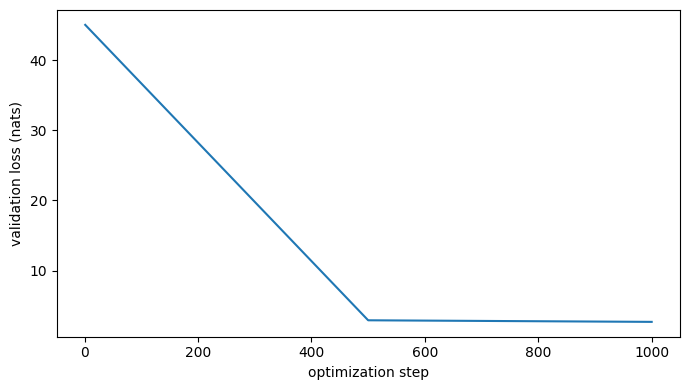

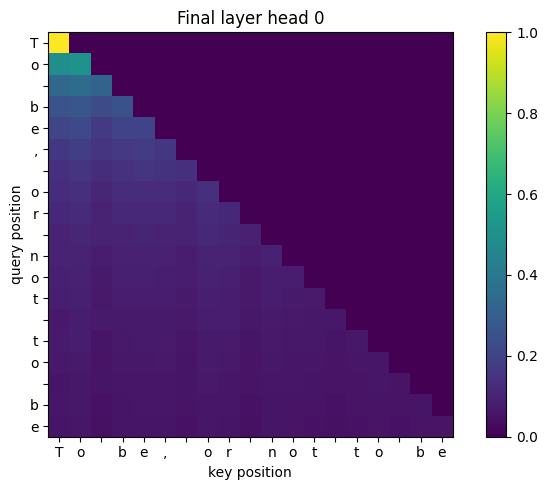

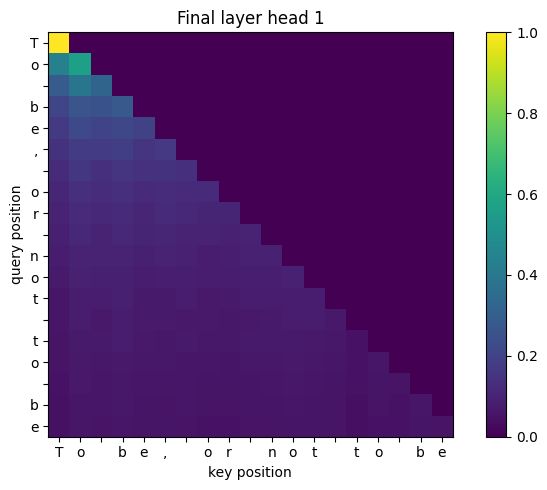

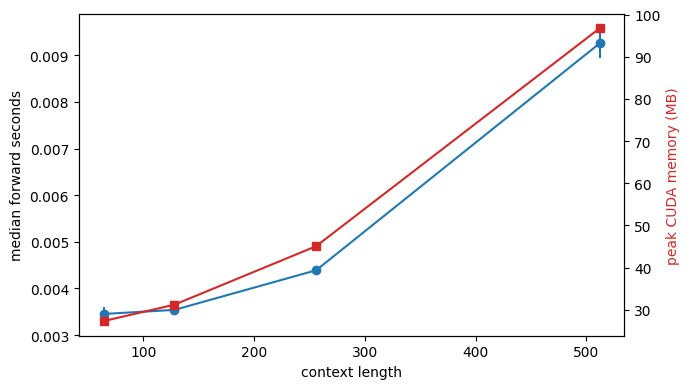

Generated sample excerpts:
--- temperature=0.2 ---
FFFFFFFF my he wis s wind wore t wor win we wis s the the wis the the the ther ar the win ther the the the the the win we me we the th win th th w h the he w w hin win the arere wore the the wis s s wis s ar s ar ar wis he o a he he o ISSSSSSSSSSSSSSSSSSSSSSS: AAAAn f ore are the t the the o we we o
--- temperature=0.8 ---
FFS: A: HHHHHoy thovilougrd thirarcees be theame s nd ho II AAest ge odorthowire s inoryourrintur f wain dd g gok horch t h n me s we wof mup f wan d caw S are hof chthis  t weran han s it, hir is hart, se ongar in he kis ou o an of orer t     To I t thethichie this, aicouf th ome ire ccou ome owe s
--- temperature=1.5 ---
IIWird. EN  That d howe,  Kat: hys thim TTaar NNRid tagongs t th t toksad ougot chnh haflliesthos, rer,IOth d,  LR: heitilswe a it d O p w r SHiguccur kn wok aife wh in ulo t p oksurikifyyo mm shoeren, hop, dyr ms f, iseSTh haisence    SS m  ik  TT ENNYEo arow tashiomyjir t rsef w k ath aase m h fe

In [ ]:
# --- Resumable Problem 2 workflow ---

import warnings

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Stable dictionaries identify matched head-count and causal-mask model configurations.
P2_HEAD_MODELS = {
    heads: f'causal-transformer-d{P2_D_MODEL}-h{heads}-l{P2_LAYERS}-c{P2_CONTEXT}'
    for heads in (1, 4, 8)
}
P2_MASK_MODELS = {
    True: f'causal-mask-d{P2_D_MODEL}-h{P2_HEADS}-l{P2_LAYERS}-c{P2_CONTEXT}',
    False: f'no-causal-mask-d{P2_D_MODEL}-h{P2_HEADS}-l{P2_LAYERS}-c{P2_CONTEXT}',
}


# Test whether one exact problem/model/optional-seed/optional-length result already exists.
def p2_result_exists(problem, model, *, seed=None, seq_len=None):
    if not RESULTS.exists():
        return False
    rows = pd.read_csv(RESULTS)
    selected = rows[rows.problem.eq(problem) & rows.model.eq(model)]
    selected = selected[selected.seed.isna()] if seed is None else selected[selected.seed.eq(seed)]
    selected = selected[selected.seq_len.isna()] if seq_len is None else selected[selected.seq_len.eq(seq_len)]
    return not selected.empty


# Retrieve the unique persisted row for an exact experiment key.
def p2_result_row(problem, model, *, seed=None, seq_len=None):
    rows = pd.read_csv(RESULTS)
    selected = rows[rows.problem.eq(problem) & rows.model.eq(model)]
    selected = selected[selected.seed.isna()] if seed is None else selected[selected.seed.eq(seed)]
    selected = selected[selected.seq_len.isna()] if seq_len is None else selected[selected.seq_len.eq(seq_len)]
    if len(selected) != 1:
        raise RuntimeError(f'Expected one {problem}/{model} result, found {len(selected)}')
    return selected.iloc[0].to_dict()


# Compare no, sinusoidal, and learned positions using the same subject split within each seed.
def run_har_position_comparison():
    new_rows = []
    for seed in SEEDS:
        # One seed-specific split is shared by all three positional variants for fairness.
        data = load_har(ROOT / 'data', validation_seed=seed)
        for positional, model_name in zip(
            ('none', 'sinusoidal', 'learned'), P2_HAR_MODELS
        ):
            if p2_result_exists('P2-HAR', model_name, seed=seed):
                continue
            set_seed(seed)
            encoder = EncoderClassifier(
                d_model=P2_D_MODEL, n_heads=P2_HEADS, n_layers=P2_LAYERS,
                positional=positional, max_len=P2_CONTEXT + 2,
            ).to(DEVICE)
            encoder, curve, seconds = train_model(
                encoder, data['x_train'], data['y_train'], data['x_val'], data['y_val'],
                task='classification', epochs=P2_HAR_EPOCHS,
                batch_size=P2_HAR_BATCH_SIZE, device=DEVICE,
            )
            with torch.no_grad():
                predictions = encoder(
                    torch.from_numpy(data['x_test']).to(DEVICE)
                ).argmax(1).cpu().numpy()
            row = {
                'problem': 'P2-HAR', 'model': model_name, 'seed': seed,
                'test_acc': accuracy_score(data['y_test'], predictions),
                'macro_f1': f1_score(
                    data['y_test'], predictions, average='macro', zero_division=0
                ),
                'params': sum(parameter.numel() for parameter in encoder.parameters()),
                'sec_per_epoch': seconds,
                'notes': (
                    f'd_model={P2_D_MODEL};heads={P2_HEADS};layers={P2_LAYERS};'
                    f'epochs={P2_HAR_EPOCHS};batch_size={P2_HAR_BATCH_SIZE};'
                    f'best_val_loss={min(curve):.6f};split_seed={seed};'
                    f'validation_subjects={data["val_subjects"].tolist()}'
                ),
            }
            append_result(RESULTS, row)
            new_rows.append(row)
    return new_rows


# Select only current h=64 Problem 1 and current Problem 2 HAR rows for comparison.
def current_har_rows():
    results = pd.read_csv(RESULTS)
    p1_hidden = 64
    p1_input = 9
    p1_classes = 6
    gates = {'RNN': 1, 'LSTM': 4, 'GRU': 3}
    p1_params = {
        kind: gates[kind] * p1_hidden * (p1_input + p1_hidden + 1)
        + gates[kind] * p1_hidden + p1_hidden * p1_classes + p1_classes
        for kind in gates
    }
    # Parameter counts exclude stale Problem 1 rows from older recurrent widths.
    p1 = results[
        results.problem.eq('P1-HAR')
        & results.seed.isin(SEEDS)
        & results.model.isin(p1_params)
        & results.apply(lambda row: row['params'] == p1_params.get(row['model']), axis=1)
    ]
    p2 = results[
        results.problem.eq('P2-HAR')
        & results.seed.isin(SEEDS)
        & results.model.isin(P2_HAR_MODELS)
    ]
    return pd.concat((p1, p2), ignore_index=True)


# Plot the best seed-mean HAR model from each problem when both inventories are complete.
def plot_har_cross_problem_comparison():
    har = current_har_rows()
    summaries = har.groupby(['problem', 'model']).agg(
        acc_mean=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
        f1_mean=('macro_f1', 'mean'), f1_std=('macro_f1', 'std'),
        params=('params', 'mean'), sec_per_epoch=('sec_per_epoch', 'mean'),
        seeds=('seed', 'nunique'),
    )
    summaries = summaries[summaries.seeds.eq(len(SEEDS))]
    if not {'P1-HAR', 'P2-HAR'}.issubset(summaries.index.get_level_values('problem')):
        return
    best_p1_name = summaries.loc['P1-HAR'].acc_mean.idxmax()
    best_p2_name = summaries.loc['P2-HAR'].acc_mean.idxmax()
    comparison = pd.concat([
        summaries.loc[[('P1-HAR', best_p1_name)]],
        summaries.loc[[('P2-HAR', best_p2_name)]],
    ])
    labels = [f'Problem 1\n{best_p1_name}', f'Problem 2\n{best_p2_name}']
    plt.figure(figsize=(7, 4))
    bars = plt.bar(labels, comparison.acc_mean, yerr=comparison.acc_std, capsize=5)
    plt.bar_label(bars, labels=[f'{value:.4f}' for value in comparison.acc_mean], padding=3)
    plt.ylabel('test accuracy (mean ± seed std)')
    plt.title('Best recurrent HAR model vs best Transformer variant')
    plt.ylim(max(0, comparison.acc_mean.min() - 0.1), min(1.0, comparison.acc_mean.max() + 0.08))
    plt.tight_layout()
    plt.savefig(P2_FIGURES / 'har_transformer_vs_best_p1.png', dpi=160)
    plt.show()


# Encode all architecture and budget fields into a checkpoint filename.
def checkpoint_path(*, heads, causal, steps, label):
    causal_tag = 'causal' if causal else 'unmasked'
    filename = (
        f'{label}-d{P2_D_MODEL}-h{heads}-l{P2_LAYERS}-'
        f'c{P2_CONTEXT}-steps{steps}-{causal_tag}.pt'
    )
    return P2_CHECKPOINTS / filename


# Load the exact base-LM checkpoint or train and save its state, history, timing, and config.
def train_or_load_base_lm(train_tokens, val_tokens, vocab_size):
    path = checkpoint_path(
        heads=P2_HEADS, causal=True, steps=LM_STEPS, label='base-lm'
    )
    set_seed(SEEDS[0])
    model = CausalTransformerLM(
        vocab_size, d_model=P2_D_MODEL, n_heads=P2_HEADS,
        n_layers=P2_LAYERS, context=P2_CONTEXT, causal=True,
    ).to(DEVICE)
    if path.exists():
        payload = torch.load(path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(payload['state_dict'])
        return model, payload['history'], float(payload['elapsed'])
    model, history, elapsed = train_language_model(
        model, train_tokens, val_tokens, steps=LM_STEPS, eval_every=500,
        batch_size=P2_LM_BATCH_SIZE, device=DEVICE,
    )
    torch.save({
        'state_dict': {name: value.detach().cpu() for name, value in model.state_dict().items()},
        'history': history, 'elapsed': elapsed,
        'config': {
            'd_model': P2_D_MODEL, 'heads': P2_HEADS, 'layers': P2_LAYERS,
            'context': P2_CONTEXT, 'steps': LM_STEPS, 'causal': True,
        },
    }, path)
    return model, history, elapsed


# Load or train one matched-budget head/mask ablation and compute deterministic losses.
def train_or_load_ablation_model(
    train_tokens, val_tokens, vocab_size, *, heads, causal
):
    path = checkpoint_path(
        heads=heads, causal=causal, steps=ABLATION_STEPS, label='ablation-lm'
    )
    set_seed(SEEDS[0])
    model = CausalTransformerLM(
        vocab_size, d_model=P2_D_MODEL, n_heads=heads,
        n_layers=P2_LAYERS, context=P2_CONTEXT, causal=causal,
    ).to(DEVICE)
    if path.exists():
        payload = torch.load(path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(payload['state_dict'])
        history = payload['history']
        elapsed = float(payload['elapsed'])
    else:
        model, history, elapsed = train_language_model(
            model, train_tokens, val_tokens, steps=ABLATION_STEPS,
            eval_every=500, batch_size=P2_LM_BATCH_SIZE, device=DEVICE,
        )
        torch.save({
            'state_dict': {name: value.detach().cpu() for name, value in model.state_dict().items()},
            'history': history, 'elapsed': elapsed,
            'config': {
                'd_model': P2_D_MODEL, 'heads': heads, 'layers': P2_LAYERS,
                'context': P2_CONTEXT, 'steps': ABLATION_STEPS, 'causal': causal,
            },
        }, path)
    metrics = estimate_loss(
        model, train_tokens, val_tokens, batches=100,
        batch_size=P2_LM_BATCH_SIZE, device=DEVICE, seed=SEEDS[-1],
    )
    return model, history, elapsed, metrics


# Measure CPU forward median/std only; this helper does not claim a peak-memory metric.
def cpu_context_profile(
    model_factory, lengths=(64, 128, 256, 512), *,
    batch_size=8, warmup=5, repeats=20,
):
    records = []
    for length in lengths:
        model = model_factory(length).to('cpu').eval()
        inputs = torch.randint(0, model.token_embedding.num_embeddings, (batch_size, length))
        with torch.no_grad():
            for _ in range(warmup):
                model(inputs)
        timings = []
        with torch.no_grad():
            for _ in range(repeats):
                started = time.perf_counter(); model(inputs)
                timings.append(time.perf_counter() - started)
        records.append({
            'context': float(length), 'seconds_median': float(np.median(timings)),
            'seconds_std': float(np.std(timings)), 'peak_memory_mb': None,
        })
    return records


# Persist each context timing and optional CUDA peak in the notes field once.
def record_context_profile(profile):
    for record in profile:
        length = int(record['context'])
        if p2_result_exists('P2-context-profile', P2_BASE_MODEL, seq_len=length):
            continue
        peak_memory = record['peak_memory_mb']
        memory_note = (
            'peak_cuda_memory_mb=unavailable;'
            if peak_memory is None else f'peak_cuda_memory_mb={peak_memory:.3f};'
        )
        append_result(RESULTS, {
            'problem': 'P2-context-profile', 'model': P2_BASE_MODEL,
            'seq_len': length,
            'notes': (
                f'd_model={P2_D_MODEL};heads={P2_HEADS};layers={P2_LAYERS};'
                f"forward_seconds_median={record['seconds_median']:.6f};"
                f"forward_seconds_std={record['seconds_std']:.6f};"
                f'{memory_note}warmup=5;repeats=20'
            ),
        })


# Quantify sample diversity and pathological repeated-character runs.
def generation_diagnostics(sample):
    bigrams = [sample[index:index + 2] for index in range(max(0, len(sample) - 1))]
    longest_run = 0
    current_run = 0
    previous = None
    for character in sample:
        current_run = current_run + 1 if character == previous else 1
        longest_run = max(longest_run, current_run)
        previous = character
    return {
        'unique_characters': len(set(sample)),
        'unique_bigram_ratio': len(set(bigrams)) / max(1, len(bigrams)),
        'longest_repeated_character_run': longest_run,
    }


# Warn about runtime only; CPU preserves every architecture and training budget.
if DEVICE != 'cuda':
    warnings.warn(
        'CUDA is unavailable; the fixed d=64 workflow remains unchanged on CPU. '
        'The 1,000-step base LM and 500-step ablations use batch size 8 and may take hours.',
        RuntimeWarning, stacklevel=1,
    )

# Stage 1: run/resume positional HAR variants and compare current P1/P2 seed aggregates.
har_new_rows = run_har_position_comparison()
plot_har_cross_problem_comparison()

# Stage 2: encode Shakespeare, restore/train the principal LM, and persist nats plus BPC.
text = download_tiny_shakespeare(ROOT / 'data' / 'tinyshakespeare.txt')
train_tokens, val_tokens, stoi = encode_shakespeare(text)
itos = {index: char for char, index in stoi.items()}
assert len(stoi) == 65, f'Expected 65 characters, got {len(stoi)}'
lm, history, elapsed = train_or_load_base_lm(train_tokens, val_tokens, len(stoi))
metrics = estimate_loss(
    lm, train_tokens, val_tokens, batches=100,
    batch_size=P2_LM_BATCH_SIZE, device=DEVICE, seed=SEEDS[-1],
)
val_nats = metrics['val']
if not p2_result_exists(
    'P2-language-model', P2_BASE_MODEL, seed=SEEDS[0], seq_len=P2_CONTEXT
):
    append_result(RESULTS, {
        'problem': 'P2-language-model', 'model': P2_BASE_MODEL,
        'seed': SEEDS[0], 'seq_len': P2_CONTEXT,
        'params': sum(parameter.numel() for parameter in lm.parameters()),
        'val_loss_nats': val_nats, 'bits_per_char': val_nats / math.log(2),
        'notes': (
            f'd_model={P2_D_MODEL};heads={P2_HEADS};layers={P2_LAYERS};'
            f'steps={LM_STEPS};context={P2_CONTEXT};batch_size={P2_LM_BATCH_SIZE};'
            f'sec_per_step={elapsed / LM_STEPS:.6f};checkpoint=lowest_deterministic_val_loss'
        ),
    })

# Plot the restored base model's deterministic validation-loss history.
plt.figure(figsize=(7, 4))
plt.plot([point['step'] for point in history], [point['val'] for point in history])
plt.xlabel('optimization step'); plt.ylabel('validation loss (nats)'); plt.tight_layout()
plt.savefig(P2_FIGURES / 'shakespeare_learning_curve.png', dpi=160); plt.show()

# Stage 3: generate matched-length samples at low, medium, and high temperatures.
start = train_tokens[:1].unsqueeze(0).to(DEVICE)
samples = []
with P2_SAMPLES.open('w', encoding='utf-8') as output_file:
    for sample_seed, temperature in enumerate((0.2, 0.8, 1.5), start=SEEDS[-1]):
        set_seed(sample_seed)
        sampled = generate(lm, start, max_new_tokens=500, temperature=temperature, top_k=20)[0]
        sample = ''.join(itos[int(token)] for token in sampled[-500:].cpu())
        output_file.write(f'Temperature {temperature}\n{sample}\n\n')
        samples.append((temperature, sample))

# Stage 4: inspect two final-layer heads; heatmap rows are queries and columns are keys.
sentence = 'To be, or not to be'
sentence_ids = torch.tensor([[stoi[char] for char in sentence]], device=DEVICE)
with torch.no_grad():
    _, all_attention = lm(sentence_ids, return_attention=True)
attention_lines = []
for head in (0, 1):
    matrix = all_attention[-1][0, head].detach().cpu()
    diagonal_mean = float(matrix.diag().mean())
    previous_mean = float(matrix.diagonal(offset=-1).mean())
    nonself_mask = torch.tril(torch.ones_like(matrix, dtype=torch.bool), diagonal=-1)
    causal_nonself = matrix.masked_fill(~nonself_mask, -torch.inf)
    query_position, key_position = divmod(int(causal_nonself.argmax()), matrix.shape[1])
    strongest_weight = float(matrix[query_position, key_position])
    attention_lines.append(
        f'head={head};mean_self_attention={diagonal_mean:.6f};'
        f'mean_previous_token_attention={previous_mean:.6f};'
        f'strongest_nonself_weight={strongest_weight:.6f};'
        f'query_position={query_position};query_character={sentence[query_position]!r};'
        f'key_position={key_position};key_character={sentence[key_position]!r}'
    )
    plt.figure(figsize=(7, 5)); plt.imshow(matrix, cmap='viridis')
    plt.xticks(range(len(sentence)), list(sentence)); plt.yticks(range(len(sentence)), list(sentence))
    plt.xlabel('key position'); plt.ylabel('query position'); plt.title(f'Final layer head {head}')
    plt.colorbar(); plt.tight_layout()
    plt.savefig(P2_FIGURES / f'attention_head_{head}.png', dpi=160); plt.show()
P2_ATTENTION_ANALYSIS.write_text(
    'Sentence: ' + repr(sentence) + '\nAxes: rows=query positions; columns=key positions. '
    'The causal upper triangle is masked.\n' + '\n'.join(attention_lines) + '\n',
    encoding='utf-8',
)

# Construct a fixed-width model whose context changes only for profiling.
def make_profile_model(context):
    return CausalTransformerLM(
        len(stoi), d_model=P2_D_MODEL, n_heads=P2_HEADS,
        n_layers=P2_LAYERS, context=context,
    )


# Stage 5: profile contexts; CUDA records peak allocation while CPU records timing only here.
profile = (
    attention_memory_profile(make_profile_model, device=DEVICE)
    if DEVICE == 'cuda' else cpu_context_profile(make_profile_model)
)
record_context_profile(profile)
contexts = [record['context'] for record in profile]
medians = [record['seconds_median'] for record in profile]
spreads = [record['seconds_std'] for record in profile]
memories = [record['peak_memory_mb'] for record in profile]
figure, time_axis = plt.subplots(figsize=(7, 4))
time_axis.errorbar(contexts, medians, yerr=spreads, marker='o')
time_axis.set_xlabel('context length'); time_axis.set_ylabel('median forward seconds')
if all(memory is not None for memory in memories):
    memory_axis = time_axis.twinx()
    memory_axis.plot(contexts, memories, marker='s', color='tab:red')
    memory_axis.set_ylabel('peak CUDA memory (MB)', color='tab:red')
else:
    time_axis.text(
        0.98, 0.05, 'Peak CUDA memory unavailable on CPU', ha='right',
        va='bottom', transform=time_axis.transAxes,
    )
figure.tight_layout(); figure.savefig(P2_FIGURES / 'context_time_memory.png', dpi=160); plt.show()

# Stage 6: train/load matched 1-, 4-, and 8-head models at fixed width and budget.
head_results = {}
head_models = {}
for heads in (1, 4, 8):
    model_name = P2_HEAD_MODELS[heads]
    variant, _, variant_elapsed, variant_metrics = train_or_load_ablation_model(
        train_tokens, val_tokens, len(stoi), heads=heads, causal=True
    )
    head_models[heads] = variant
    if p2_result_exists(
        'P2-head-ablation', model_name, seed=SEEDS[0], seq_len=P2_CONTEXT
    ):
        variant_val = float(p2_result_row(
            'P2-head-ablation', model_name, seed=SEEDS[0], seq_len=P2_CONTEXT
        )['val_loss_nats'])
    else:
        variant_val = variant_metrics['val']
        append_result(RESULTS, {
            'problem': 'P2-head-ablation', 'model': model_name,
            'seed': SEEDS[0], 'seq_len': P2_CONTEXT,
            'params': sum(parameter.numel() for parameter in variant.parameters()),
            'val_loss_nats': variant_val, 'bits_per_char': variant_val / math.log(2),
            'notes': (
                f'd_model={P2_D_MODEL};heads={heads};layers={P2_LAYERS};'
                f'context={P2_CONTEXT};steps={ABLATION_STEPS};'
                f'batch_size={P2_LM_BATCH_SIZE};matched_budget=True;'
                f'sec_per_step={variant_elapsed / ABLATION_STEPS:.6f}'
            ),
        })
    head_results[heads] = variant_val

# Stage 7: compare matched four-head causal and unmasked models.
causal_model = head_models[P2_HEADS]
causal_val = head_results[P2_HEADS]
causal_mask_name = P2_MASK_MODELS[True]
unmasked_name = P2_MASK_MODELS[False]
if not p2_result_exists(
    'P2-mask-ablation', causal_mask_name, seed=SEEDS[0], seq_len=P2_CONTEXT
):
    append_result(RESULTS, {
        'problem': 'P2-mask-ablation', 'model': causal_mask_name,
        'seed': SEEDS[0], 'seq_len': P2_CONTEXT,
        'params': sum(parameter.numel() for parameter in causal_model.parameters()),
        'val_loss_nats': causal_val, 'bits_per_char': causal_val / math.log(2),
        'notes': (
            f'd_model={P2_D_MODEL};heads={P2_HEADS};layers={P2_LAYERS};'
            f'context={P2_CONTEXT};steps={ABLATION_STEPS};batch_size={P2_LM_BATCH_SIZE}'
        ),
    })
unmasked, _, unmasked_elapsed, unmasked_metrics = train_or_load_ablation_model(
    train_tokens, val_tokens, len(stoi), heads=P2_HEADS, causal=False
)
if not p2_result_exists(
    'P2-mask-ablation', unmasked_name, seed=SEEDS[0], seq_len=P2_CONTEXT
):
    unmasked_val = unmasked_metrics['val']
    append_result(RESULTS, {
        'problem': 'P2-mask-ablation', 'model': unmasked_name,
        'seed': SEEDS[0], 'seq_len': P2_CONTEXT,
        'params': sum(parameter.numel() for parameter in unmasked.parameters()),
        'val_loss_nats': unmasked_val, 'bits_per_char': unmasked_val / math.log(2),
        'notes': (
            f'd_model={P2_D_MODEL};heads={P2_HEADS};layers={P2_LAYERS};'
            f'context={P2_CONTEXT};steps={ABLATION_STEPS};batch_size={P2_LM_BATCH_SIZE};'
            f'future_token_leakage=True;sec_per_step={unmasked_elapsed / ABLATION_STEPS:.6f}'
        ),
    })

# Generate matched causal/unmasked samples with the same prompt and sampling seed.
prompt_text = 'ROMEO:'
prompt_tokens = torch.tensor([[stoi[char] for char in prompt_text]], device=DEVICE)
mask_samples = {}
for label, model in ((causal_mask_name, causal_model), (unmasked_name, unmasked)):
    set_seed(SEEDS[-1])
    generated = generate(model, prompt_tokens, max_new_tokens=500, temperature=0.8, top_k=20)[0]
    mask_samples[label] = ''.join(itos[int(token)] for token in generated[-500:].cpu())
with P2_MASK_SAMPLES.open('w', encoding='utf-8') as output_file:
    output_file.write(
        f'prompt={prompt_text!r};temperature=0.8;top_k=20;sampling_seed={SEEDS[-1]};'
        f'steps={ABLATION_STEPS}\n\n'
    )
    for label, sample in mask_samples.items():
        diagnostics = generation_diagnostics(sample)
        output_file.write(f'[{label}]\n')
        output_file.write(';'.join(
            f'{key}={value:.6f}' if isinstance(value, float) else f'{key}={value}'
            for key, value in diagnostics.items()
        ) + '\n')
        output_file.write(sample + '\n\n')

# Print short excerpts while preserving complete samples in the text artifact.
print('Generated sample excerpts:')
for temperature, sample in samples:
    print(f'--- temperature={temperature} ---\n{sample[:300].replace(chr(10), " ")}')

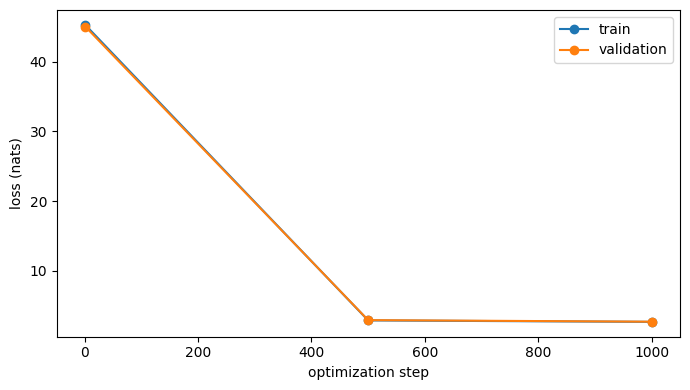

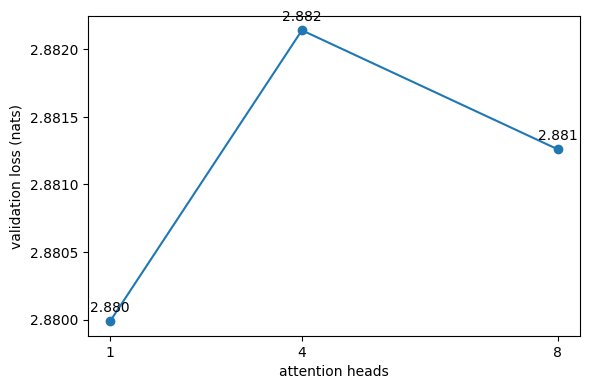

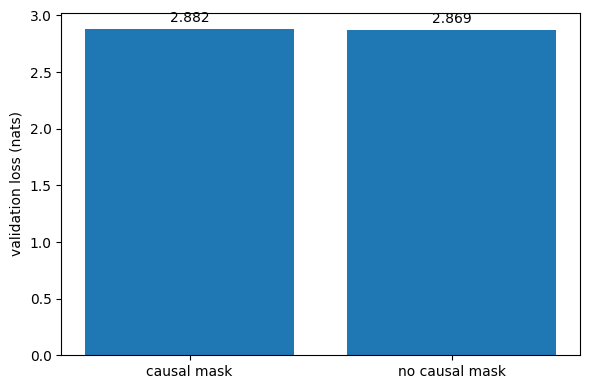

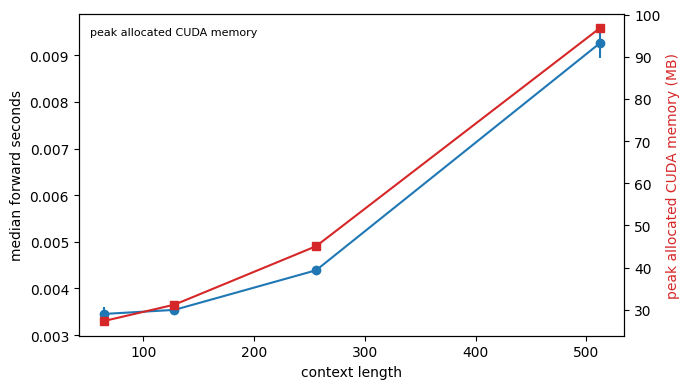

In [ ]:
# --- Plotting and device-specific profiling evidence ---

# Plot deterministic train/validation loss estimates across optimization checkpoints.
plt.figure(figsize=(7, 4))
steps = [point['step'] for point in history]
plt.plot(steps, [point['train'] for point in history], marker='o', label='train')
plt.plot(steps, [point['val'] for point in history], marker='o', label='validation')
plt.xlabel('optimization step'); plt.ylabel('loss (nats)'); plt.legend()
plt.tight_layout()
plt.savefig(P2_FIGURES / 'shakespeare_learning_curve.png', dpi=160)
plt.show()

# Plot matched-budget validation loss against attention-head count.
head_counts = np.asarray(sorted(head_results))
head_losses = np.asarray([head_results[heads] for heads in head_counts])
plt.figure(figsize=(6, 4))
plt.plot(head_counts, head_losses, marker='o')
for heads, loss in zip(head_counts, head_losses):
    plt.annotate(
        f'{loss:.3f}', (heads, loss), xytext=(0, 7),
        textcoords='offset points', ha='center',
    )
plt.xticks(head_counts); plt.xlabel('attention heads'); plt.ylabel('validation loss (nats)')
plt.tight_layout()
plt.savefig(P2_FIGURES / 'heads_ablation.png', dpi=160)
plt.show()

# Plot the exact current causal and unmasked four-head validation losses.
mask_rows = pd.read_csv(RESULTS)
mask_rows = mask_rows[
    mask_rows.problem.eq('P2-mask-ablation')
    & mask_rows.model.isin(P2_MASK_MODELS.values())
    & mask_rows.seed.eq(SEEDS[0])
    & mask_rows.seq_len.eq(P2_CONTEXT)
]
mask_rows = mask_rows.set_index('model')
mask_labels = [P2_MASK_MODELS[True], P2_MASK_MODELS[False]]
mask_losses = mask_rows.loc[mask_labels, 'val_loss_nats'].astype(float)
plt.figure(figsize=(6, 4))
bars = plt.bar(['causal mask', 'no causal mask'], mask_losses)
plt.bar_label(bars, fmt='%.3f', padding=3)
plt.ylabel('validation loss (nats)'); plt.tight_layout()
plt.savefig(P2_FIGURES / 'no_mask_result.png', dpi=160)
plt.show()


# Profile CPU timing and positive self-allocation volume for one forward pass per context.
def cpu_allocation_profile(
    model_factory, lengths=(64, 128, 256, 512), *,
    batch_size=8, warmup=5, repeats=20,
):
    from torch.profiler import ProfilerActivity, profile as torch_profile

    records = []
    for length in lengths:
        model = model_factory(length).to('cpu').eval()
        inputs = torch.randint(
            0, model.token_embedding.num_embeddings, (batch_size, length)
        )
        with torch.no_grad():
            # Warm up first, then collect repeated wall-clock samples and one memory profile.
            for _ in range(warmup):
                model(inputs)
            timings = []
            for _ in range(repeats):
                started = time.perf_counter()
                model(inputs)
                timings.append(time.perf_counter() - started)
            with torch_profile(
                activities=[ProfilerActivity.CPU], profile_memory=True
            ) as profiler:
                model(inputs)
        # Sum positive operator self allocations; this is allocation volume, not peak RSS.
        allocated_bytes = sum(
            max(0, event.self_cpu_memory_usage)
            for event in profiler.key_averages()
        )
        records.append({
            'context': float(length),
            'seconds_median': float(np.median(timings)),
            'seconds_std': float(np.std(timings)),
            'peak_cuda_memory_mb': None,
            'cpu_positive_self_allocated_mb': allocated_bytes / (1024 ** 2),
            'memory_metric': 'PyTorch profiler positive self CPU allocation volume',
        })
    return records


# Update each current context row with its CPU allocation metric without duplicating note keys.
def persist_cpu_profile_notes(records):
    import re

    results = pd.read_csv(RESULTS, dtype=str, keep_default_na=False)
    if tuple(results.columns) != RESULT_COLUMNS:
        raise ValueError('results.csv does not have the expected 12-column schema')
    numeric_seq_lengths = pd.to_numeric(results['seq_len'], errors='coerce')
    note_key = 'cpu_positive_self_allocated_mb'
    note_pattern = re.compile(rf'^{re.escape(note_key)}=.*$')
    for record in records:
        seq_len = int(record['context'])
        matches = (
            results['problem'].eq('P2-context-profile')
            & results['model'].eq(P2_BASE_MODEL)
            & numeric_seq_lengths.eq(seq_len)
        )
        if matches.sum() != 1:
            raise ValueError(f'Expected one current context-profile row for seq_len={seq_len}')
        row_index = results.index[matches][0]
        note_parts = [
            part for part in re.split(r';', results.at[row_index, 'notes'])
            if part and not note_pattern.fullmatch(part)
        ]
        note_parts.append(f"{note_key}={record[note_key]:.3f}")
        results.at[row_index, 'notes'] = ';'.join(note_parts)
    results.loc[:, list(RESULT_COLUMNS)].to_csv(RESULTS, index=False)


# CUDA uses true peak allocated memory; CPU uses explicitly labelled allocation volume.
if DEVICE == 'cuda':
    profile_evidence = [
        {
            **record,
            'peak_cuda_memory_mb': record['peak_memory_mb'],
            'cpu_positive_self_allocated_mb': None,
            'memory_metric': 'peak allocated CUDA memory',
        }
        for record in profile
    ]
    memory_field = 'peak_cuda_memory_mb'
    memory_label = 'peak allocated CUDA memory (MB)'
else:
    profile_evidence = cpu_allocation_profile(make_profile_model)
    persist_cpu_profile_notes(profile_evidence)
    memory_field = 'cpu_positive_self_allocated_mb'
    memory_label = 'profiled positive CPU allocation volume (MB)'

# Plot median/std forward time and the device-appropriate, clearly labelled memory metric.
contexts = [record['context'] for record in profile_evidence]
medians = [record['seconds_median'] for record in profile_evidence]
spreads = [record['seconds_std'] for record in profile_evidence]
memories = [record[memory_field] for record in profile_evidence]
figure, time_axis = plt.subplots(figsize=(7, 4))
time_axis.errorbar(contexts, medians, yerr=spreads, marker='o', label='forward time')
time_axis.set_xlabel('context length'); time_axis.set_ylabel('median forward seconds')
memory_axis = time_axis.twinx()
memory_axis.plot(contexts, memories, marker='s', color='tab:red', label=memory_label)
memory_axis.set_ylabel(memory_label, color='tab:red')
time_axis.text(
    0.02, 0.96, profile_evidence[0]['memory_metric'], va='top',
    transform=time_axis.transAxes, fontsize=8,
 )
figure.tight_layout()
figure.savefig(P2_FIGURES / 'context_time_memory.png', dpi=160)
plt.show()

In [ ]:
# --- Evidence inventory validation and rendered analysis ---

import re
from IPython.display import Markdown, display


# Parse one semicolon-delimited numeric notes field, returning None when absent.
def numeric_note(notes, key):
    match = re.search(rf'(?:^|;){re.escape(key)}=([0-9.eE+-]+)', str(notes))
    return float(match.group(1)) if match else None


# Validate exact rows/artifacts, aggregate evidence, parse diagnostics, and render the report.
def render_problem2_analysis():
    # Return early with an actionable status when the central evidence table is absent.
    if not RESULTS.exists():
        display(Markdown('## Analysis status\n\nMissing evidence: `results.csv`. Run All to resume.'))
        return

    results = pd.read_csv(RESULTS)
    missing_rows = []
    # Construct the exact 3 positional models x 3 seeds HAR inventory.
    expected_har = {
        (model, seed) for model in P2_HAR_MODELS for seed in SEEDS
    }
    # Model IDs and chosen seeds exclude rows from old Problem 2 configurations.
    actual_har = set(
        results[
            results.problem.eq('P2-HAR')
            & results.model.isin(P2_HAR_MODELS)
            & results.seed.isin(SEEDS)
        ][['model', 'seed']]
        .dropna().assign(seed=lambda frame: frame.seed.astype(int))
        .itertuples(index=False, name=None)
    )
    for key in sorted(expected_har - actual_har):
        missing_rows.append(f'P2-HAR/model={key[0]}/seed={key[1]}')

    # Require exactly one current base, head-ablation, and mask-ablation row per key.
    expected_singletons = {
        ('P2-language-model', P2_BASE_MODEL, SEEDS[0], P2_CONTEXT),
        *((
            'P2-head-ablation', P2_HEAD_MODELS[heads], SEEDS[0], P2_CONTEXT
        ) for heads in (1, 4, 8)),
        ('P2-mask-ablation', P2_MASK_MODELS[True], SEEDS[0], P2_CONTEXT),
        ('P2-mask-ablation', P2_MASK_MODELS[False], SEEDS[0], P2_CONTEXT),
    }
    for problem, model, seed, seq_len in sorted(expected_singletons):
        rows = results[
            results.problem.eq(problem) & results.model.eq(model)
            & results.seed.eq(seed) & results.seq_len.eq(seq_len)
        ]
        if len(rows) != 1:
            missing_rows.append(
                f'{problem}/model={model}/seed={seed}/seq_len={seq_len} '
                f'(found {len(rows)})'
            )
    # Require one current context-profile row at each requested sequence length.
    for seq_len in (64, 128, 256, 512):
        rows = results[
            results.problem.eq('P2-context-profile')
            & results.model.eq(P2_BASE_MODEL)
            & results.seq_len.eq(seq_len)
        ]
        if len(rows) != 1:
            missing_rows.append(
                f'P2-context-profile/model={P2_BASE_MODEL}/seq_len={seq_len} '
                f'(found {len(rows)})'
            )

    # Guard every text, figure, and configuration-specific checkpoint used as evidence.
    required_artifacts = {
        'three-temperature samples': P2_SAMPLES,
        'matched mask-generation samples': P2_MASK_SAMPLES,
        'attention summary': P2_ATTENTION_ANALYSIS,
        'attention head 0 heatmap': P2_FIGURES / 'attention_head_0.png',
        'attention head 1 heatmap': P2_FIGURES / 'attention_head_1.png',
        'HAR cross-problem comparison': P2_FIGURES / 'har_transformer_vs_best_p1.png',
        'LM learning curve': P2_FIGURES / 'shakespeare_learning_curve.png',
        'head-count figure': P2_FIGURES / 'heads_ablation.png',
        'mask-loss figure': P2_FIGURES / 'no_mask_result.png',
        'context figure': P2_FIGURES / 'context_time_memory.png',
        'base LM checkpoint': checkpoint_path(
            heads=P2_HEADS, causal=True, steps=LM_STEPS, label='base-lm'
        ),
        'one-head checkpoint': checkpoint_path(
            heads=1, causal=True, steps=ABLATION_STEPS, label='ablation-lm'
        ),
        'four-head causal checkpoint': checkpoint_path(
            heads=4, causal=True, steps=ABLATION_STEPS, label='ablation-lm'
        ),
        'eight-head checkpoint': checkpoint_path(
            heads=8, causal=True, steps=ABLATION_STEPS, label='ablation-lm'
        ),
        'unmasked checkpoint': checkpoint_path(
            heads=P2_HEADS, causal=False, steps=ABLATION_STEPS, label='ablation-lm'
        ),
    }
    missing_artifacts = [
        f'{label}: {path.relative_to(ROOT)}'
        for label, path in required_artifacts.items() if not path.exists()
    ]
    # Do not generate partial conclusions when any row or artifact is unavailable.
    if missing_rows or missing_artifacts:
        details = '\n'.join(
            f'- `{item}`' for item in [*missing_rows, *missing_artifacts]
        )
        display(Markdown(
            '## Analysis status\n\nEvidence is incomplete. Run All to resume. '
            'No final comparative conclusions are claimed.\n\n'
            '### Missing evidence\n\n' + details
        ))
        return

    # Aggregate current P1/P2 HAR accuracy, F1, parameter, and timing evidence over seeds.
    har = current_har_rows()
    har_summary = har.groupby(['problem', 'model']).agg(
        acc_mean=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
        f1_mean=('macro_f1', 'mean'), f1_std=('macro_f1', 'std'),
        params=('params', 'mean'), sec_per_epoch=('sec_per_epoch', 'mean'),
        seeds=('seed', 'nunique'),
    )
    har_summary = har_summary[har_summary.seeds.eq(len(SEEDS))]
    best_p1_name = har_summary.loc['P1-HAR'].acc_mean.idxmax()
    best_p2_name = har_summary.loc['P2-HAR'].acc_mean.idxmax()
    best_p1 = har_summary.loc[('P1-HAR', best_p1_name)]
    best_p2 = har_summary.loc[('P2-HAR', best_p2_name)]
    p2_har = har_summary.loc['P2-HAR']
    positional_lines = '\n'.join(
        f'- `{model}`: accuracy {row.acc_mean:.4f} ± {row.acc_std:.4f}; '
        f'macro-F1 {row.f1_mean:.4f} ± {row.f1_std:.4f}'
        for model, row in p2_har.iterrows()
    )

    # Select exact current base/head/mask rows for LM evidence and BPC reporting.
    base = results[
        results.problem.eq('P2-language-model')
        & results.model.eq(P2_BASE_MODEL)
        & results.seed.eq(SEEDS[0])
        & results.seq_len.eq(P2_CONTEXT)
    ].iloc[0]
    heads = results[
        results.problem.eq('P2-head-ablation')
        & results.model.isin(P2_HEAD_MODELS.values())
        & results.seed.eq(SEEDS[0])
        & results.seq_len.eq(P2_CONTEXT)
    ].sort_values('val_loss_nats')
    head_lines = '\n'.join(
        f'- `{row.model}`: {row.val_loss_nats:.4f} nats, {row.bits_per_char:.4f} BPC'
        for row in heads.itertuples()
    )
    masks = results[
        results.problem.eq('P2-mask-ablation')
        & results.model.isin(P2_MASK_MODELS.values())
        & results.seed.eq(SEEDS[0])
        & results.seq_len.eq(P2_CONTEXT)
    ].set_index('model')

    # Parse each persisted temperature sample and compute comparable generation diagnostics.
    sample_text = P2_SAMPLES.read_text(encoding='utf-8')
    temperature_sections = re.findall(
        r'Temperature ([0-9.]+)\n(.*?)(?=\n\nTemperature |\Z)',
        sample_text, flags=re.S,
    )
    temperature_lines = []
    for temperature, sample in temperature_sections:
        sample = sample.rstrip('\n')
        diagnostics = generation_diagnostics(sample)
        excerpt = sample[:120].replace('\n', ' ')
        temperature_lines.append(
            f'- T={temperature}: {diagnostics["unique_characters"]} unique characters, '
            f'unique-bigram ratio {diagnostics["unique_bigram_ratio"]:.3f}, '
            f'longest repeated-character run {diagnostics["longest_repeated_character_run"]}; '
            f'excerpt: `{excerpt}`'
        )

    # Parse labelled causal/unmasked sample sections and their persisted diagnostics.
    mask_text = P2_MASK_SAMPLES.read_text(encoding='utf-8')
    mask_sections = {}
    for label in P2_MASK_MODELS.values():
        marker = f'[{label}]\n'
        start_index = mask_text.index(marker) + len(marker)
        next_indices = [
            mask_text.find(f'[{other}]\n', start_index)
            for other in P2_MASK_MODELS.values()
        ]
        next_indices = [index for index in next_indices if index >= 0]
        end_index = min(next_indices) if next_indices else len(mask_text)
        section = mask_text[start_index:end_index].strip()
        diagnostic_line, sample = section.split('\n', 1)
        mask_sections[label] = (diagnostic_line, sample)
    mask_lines = '\n'.join(
        f'- `{label}`: {diagnostics}; excerpt: `{sample[:140].replace(chr(10), " ")}`'
        for label, (diagnostics, sample) in mask_sections.items()
    )

    # Parse only per-head attention summary lines from the persisted analysis artifact.
    attention_lines = '\n'.join(
        f'- `{line}`'
        for line in P2_ATTENTION_ANALYSIS.read_text(encoding='utf-8').splitlines()
        if line.startswith('head=')
    )

    # Parse timing and the device-specific memory note for each exact context row.
    context = results[
        results.problem.eq('P2-context-profile')
        & results.model.eq(P2_BASE_MODEL)
    ].sort_values('seq_len')
    context_lines = []
    for row in context.itertuples():
        seconds = numeric_note(row.notes, 'forward_seconds_median')
        cuda_memory = numeric_note(row.notes, 'peak_cuda_memory_mb')
        cpu_volume = numeric_note(row.notes, 'cpu_positive_self_allocated_mb')
        memory_text = (
            f'peak CUDA memory {cuda_memory:.3f} MB' if cuda_memory is not None
            else f'positive CPU allocation volume {cpu_volume:.3f} MB (not peak memory)'
            if cpu_volume is not None else 'memory metric unavailable'
        )
        context_lines.append(
            f'- T={int(row.seq_len)}: median forward {seconds:.6f}s; {memory_text}'
        )

    seed_text = ', '.join(str(seed) for seed in SEEDS)
    causal_name = P2_MASK_MODELS[True]
    unmasked_name = P2_MASK_MODELS[False]
    # Assemble configuration, HAR, LM/BPC, samples, ablations, attention, and profile sections.
    analysis = f'''## Evidence-based interpretation

### Current configuration

All reported rows use $d={P2_D_MODEL}$, {P2_HEADS} heads, {P2_LAYERS} layers, context {P2_CONTEXT}, and seeds ({seed_text}) where three-seed runs are required. The width is divisible by 1, 4, and 8.

### HAR positional comparison

{positional_lines}

`{best_p2_name}` has the highest mean Transformer test accuracy across the three chosen seeds.

### Transformer versus best Problem 1 HAR model

Problem 1 `{best_p1_name}` achieved **{best_p1.acc_mean:.4f} ± {best_p1.acc_std:.4f} accuracy** and **{best_p1.f1_mean:.4f} ± {best_p1.f1_std:.4f} macro-F1**, with {best_p1.params:.0f} parameters and {best_p1.sec_per_epoch:.3f} sec/epoch. Problem 2 `{best_p2_name}` achieved **{best_p2.acc_mean:.4f} ± {best_p2.acc_std:.4f} accuracy** and **{best_p2.f1_mean:.4f} ± {best_p2.f1_std:.4f} macro-F1**, with {best_p2.params:.0f} parameters and {best_p2.sec_per_epoch:.3f} sec/epoch.

### Base language model and temperature

The {LM_STEPS}-step restored base checkpoint achieved **{base.val_loss_nats:.4f} nats** or **{base.bits_per_char:.4f} bits/character**, using BPC = nats / ln(2).

{chr(10).join(temperature_lines)}

### Head-count ablation

{head_lines}

The lowest matched {ABLATION_STEPS}-step validation loss is `{heads.iloc[0].model}` at **{heads.iloc[0].val_loss_nats:.4f} nats**.

### Causal-mask ablation

The matched losses are **{masks.loc[causal_name, 'val_loss_nats']:.4f} nats** with the causal mask and **{masks.loc[unmasked_name, 'val_loss_nats']:.4f} nats** without it.

{mask_lines}

Unmasked training exposes future target tokens and is invalid for autoregressive prediction.

### Final-layer attention heads

Heatmap rows are query positions and columns are key positions. Causal masking makes future keys unavailable.

{attention_lines}

### Context time and memory trend

{chr(10).join(context_lines)}

The attention score matrix has quadratic size in context length; CPU allocation volume and CUDA peak allocated memory are deliberately labelled as different metrics.
'''
    display(Markdown(analysis))


# Render immediately only when this final report cell is explicitly executed.
render_problem2_analysis()

NameError: name 'RESULTS' is not defined

## Submission status

The implementation and lightweight correctness checks are complete. To complete the submission:

1. Restart the kernel and run all cells once, in order, on either CPU or CUDA. CUDA is strongly recommended for speed; CPU execution may take several hours.
2. Confirm the final inventory reports no missing rows or artifacts: 9 HAR rows, 1 principal LM row, 4 context-profile rows, 3 head-ablation rows, 2 paired mask-ablation rows, resumable checkpoints, and all listed figures/text outputs.
3. Review the generated evidence-based interpretation, whose qualitative sample and attention discussion is computed from persisted diagnostics.
4. Export the freshly executed notebook to HTML.